# Étapes 1 et 2 : préparation et exploration des données

Produit `data/processed/table_propre.csv` (un enfant par ligne : chemin de l'IRM, site, diagnostic, âge, sexe, QI).

In [1]:
import pandas as pd
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path

print("pandas", pd.__version__)
print("nibabel", nib.__version__)

pandas 3.1.1
nibabel 5.4.2


## 1. Tableau propre

In [2]:
#trouver et compter les IRM
RAW = Path("../data/raw")

lignes = []
for f in RAW.rglob("*_T1w.nii.gz"):
    parties = f.relative_to(RAW).parts      # ex: ('NYU', 'sub-123', 'ses-1', 'anat', 'fichier')
    lignes.append({
        "site": parties[0],
        "subject_id": parties[1].replace("sub-", ""),
        "chemin": str(f),
    })

irm = pd.DataFrame(lignes)
print("Fichiers IRM :", len(irm))
print("Enfants      :", irm["subject_id"].nunique())
irm.groupby("site")["subject_id"].nunique()

Fichiers IRM : 961
Enfants      : 961


site
Brown          26
KKI            83
NYU           263
NeuroIMAGE     73
OHSU          113
Peking_1      136
Peking_2       67
Peking_3       42
Pittsburgh     98
WashU          60
Name: subject_id, dtype: int64

In [3]:
csvs = sorted((RAW / "phenotypic").glob("*.csv"))
print("CSV trouvés :", len(csvs))

morceaux = []
for c in csvs:
    df = pd.read_csv(c, dtype=str, encoding="latin-1", sep=None, engine="python")
    df["fichier_source"] = c.name
    print(f"{c.name:35s} lignes={len(df):4d}  colonnes={df.shape[1]}")
    morceaux.append(df)

pheno = pd.concat(morceaux, ignore_index=True)
print("\nTotal lignes :", len(pheno))
print("\nColonnes :")
for col in pheno.columns:
    print("  -", col)
pheno.head()

CSV trouvés : 9
Brown_TestRelease_phenotypic.csv    lignes=  26  colonnes=24
KKI_phenotypic.csv                  lignes=  83  colonnes=24
NeuroIMAGE_phenotypic.csv           lignes=  48  colonnes=24
NYU_phenotypic.csv                  lignes= 222  colonnes=24
OHSU_phenotypic.csv                 lignes=  79  colonnes=24
OHSU_TestRelease_phenotypic.csv     lignes=  34  colonnes=24
Peking_1_phenotypic.csv             lignes=  85  colonnes=24
Peking_1_TestRelease_phenotypic.csv lignes=  51  colonnes=24
Pittsburgh_phenotypic.csv           lignes=  89  colonnes=24

Total lignes : 717

Colonnes :
  - ScanDir ID
  - Site
  - Gender
  - Age
  - Handedness
  - DX
  - Secondary Dx 
  - ADHD Measure
  - ADHD Index
  - Inattentive
  - Hyper/Impulsive
  - IQ Measure
  - Verbal IQ
  - Performance IQ
  - Full2 IQ
  - Full4 IQ
  - Med Status
  - QC_Rest_1
  - QC_Rest_2
  - QC_Rest_3
  - QC_Rest_4
  - QC_Anatomical_1
  - QC_Anatomical_2
  - fichier_source
  - ID


,ScanDir ID,Site,Gender,Age,Handedness,DX,Secondary Dx,ADHD Measure,ADHD Index,Inattentive,...,Full4 IQ,Med Status,QC_Rest_1,QC_Rest_2,QC_Rest_3,QC_Rest_4,QC_Anatomical_1,QC_Anatomical_2,fichier_source,ID
0,26001,2,1,16.92,1,pending,pending,pending,pending,pending,...,120,pending,1,NaN,NaN,NaN,1,NaN,Brown_TestRelease_phenotypic.csv,NaN
1,26002,2,1,15.68,1,pending,pending,pending,pending,pending,...,107,pending,1,NaN,NaN,NaN,1,NaN,Brown_TestRelease_phenotypic.csv,NaN
2,26004,2,0,14.99,1,pending,pending,pending,pending,pending,...,125,pending,1,NaN,NaN,NaN,1,NaN,Brown_TestRelease_phenotypic.csv,NaN
3,26005,2,0,15.16,1,pending,pending,pending,pending,pending,...,126,pending,1,NaN,NaN,NaN,1,NaN,Brown_TestRelease_phenotypic.csv,NaN
4,26009,2,1,16.91,0,pending,pending,pending,pending,pending,...,97,pending,1,NaN,NaN,NaN,1,NaN,Brown_TestRelease_phenotypic.csv,NaN


In [4]:
def normaliser(serie):
    # texte, sans espaces, sans ".0" final, sur 7 chiffres (zéros devant)
    return (serie.astype(str).str.strip()
                 .str.replace(r"\.0$", "", regex=True)
                 .str.zfill(7))

pheno.columns = pheno.columns.str.strip()
pheno["ScanDir ID"] = pheno["ScanDir ID"].fillna(pheno["ID"])
pheno["subject_id"] = normaliser(pheno["ScanDir ID"])
irm["subject_id"]   = normaliser(irm["subject_id"])

ids_irm  = set(irm["subject_id"])
ids_csv  = set(pheno["subject_id"])

print("Enfants avec IRM          :", len(ids_irm))
print("Lignes dans les CSV       :", len(pheno))
print("Enfants uniques dans CSV  :", len(ids_csv))
print("Présents dans les deux    :", len(ids_irm & ids_csv))
print("IRM sans ligne dans CSV   :", len(ids_irm - ids_csv))
print("Lignes CSV sans IRM       :", len(ids_csv - ids_irm))

Enfants avec IRM          : 961
Lignes dans les CSV       : 717
Enfants uniques dans CSV  : 717
Présents dans les deux    : 717
IRM sans ligne dans CSV   : 244
Lignes CSV sans IRM       : 0


In [5]:
print("=== Valeurs du diagnostic (DX) ===")
print(pheno["DX"].value_counts(dropna=False))

print("\n=== Diagnostic par fichier CSV ===")
print(pd.crosstab(pheno["fichier_source"], pheno["DX"]))

for col in ["Gender", "Handedness"]:
    print(f"\n=== {col} ===")
    print(pheno[col].value_counts(dropna=False))

print("\n=== Âge ===")
print(pd.to_numeric(pheno["Age"], errors="coerce").describe())

print("\n=== Full4 IQ (valeurs les plus fréquentes) ===")
print(pheno["Full4 IQ"].value_counts(dropna=False).head(8))

=== Valeurs du diagnostic (DX) ===
DX
0          430
1          154
3           94
pending     26
2           13
Name: count, dtype: int64

=== Diagnostic par fichier CSV ===
DX                                    0   1  2   3  pending
fichier_source                                             
Brown_TestRelease_phenotypic.csv      0   0  0   0       26
KKI_phenotypic.csv                   61  16  1   5        0
NYU_phenotypic.csv                   99  77  2  44        0
NeuroIMAGE_phenotypic.csv            23  18  6   1        0
OHSU_TestRelease_phenotypic.csv      28   4  1   1        0
OHSU_phenotypic.csv                  42  23  2  12        0
Peking_1_TestRelease_phenotypic.csv  27   9  1  14        0
Peking_1_phenotypic.csv              61   7  0  17        0
Pittsburgh_phenotypic.csv            89   0  0   0        0

=== Gender ===
Gender
1      401
0      315
NaN      1
Name: count, dtype: int64

=== Handedness ===
Handedness
1       496
0        19
0.91     15
0.82     11
0.83

In [6]:
#retrouver les IRM sans ligne correspondante dans les CSV
manquants = irm[~irm["subject_id"].isin(ids_csv)]
print(manquants.groupby("site")["subject_id"].nunique())

site
NYU           41
NeuroIMAGE    25
Peking_2      67
Peking_3      42
Pittsburgh     9
WashU         60
Name: subject_id, dtype: int64


In [7]:
# La ligne sans identifiant
print(pheno[pheno["ScanDir ID"].isna()])

Empty DataFrame
Columns: [ScanDir ID, Site, Gender, Age, Handedness, DX, Secondary Dx, ADHD Measure, ADHD Index, Inattentive, Hyper/Impulsive, IQ Measure, Verbal IQ, Performance IQ, Full2 IQ, Full4 IQ, Med Status, QC_Rest_1, QC_Rest_2, QC_Rest_3, QC_Rest_4, QC_Anatomical_1, QC_Anatomical_2, fichier_source, ID, subject_id]
Index: []

[0 rows x 26 columns]


In [8]:
# Toutes les lignes dont l'identifiant apparaît plusieurs fois
masque = pheno.duplicated(subset="subject_id", keep=False)
dups = pheno[masque].sort_values("subject_id")
print("Lignes impliquées dans un doublon :", len(dups))
print(dups[["subject_id", "fichier_source", "DX", "Age"]].head(20))
print(dups["fichier_source"].value_counts())

Lignes impliquées dans un doublon : 0
Empty DataFrame
Columns: [subject_id, fichier_source, DX, Age]
Index: []
Series([], Name: count, dtype: int64)


In [9]:
# Les copies d'un même enfant se contredisent-elles ?
cols = ["DX", "Age", "Gender", "Handedness", "Full4 IQ"]
nb_valeurs = dups.groupby("subject_id")[cols].nunique(dropna=False)
contradictoires = nb_valeurs.max(axis=1) > 1
print("Enfants dont les copies se contredisent :", contradictoires.sum())

Enfants dont les copies se contredisent : 0


In [10]:
pheno = pheno[pheno["ScanDir ID"].notna()]                 # retire la ligne sans identifiant
pheno = pheno.drop_duplicates(subset="subject_id", keep="first")
print("Lignes après nettoyage :", len(pheno), "| uniques :", pheno["subject_id"].nunique())

Lignes après nettoyage : 717 | uniques : 717


In [11]:
#Binariser le diagnostic : 0 = pas de TDAH, 1 = TDAH
pheno = pheno[pheno["DX"] != "pending"].copy()
pheno["DX_num"] = pd.to_numeric(pheno["DX"])
pheno["adhd"] = (pheno["DX_num"] > 0).astype(int)
print(pheno["adhd"].value_counts())

adhd
0    430
1    261
Name: count, dtype: int64


In [12]:
#convertir certaines colonnes en numérique, avec NaN si conversion impossible
for col in ["Age", "Gender", "Full4 IQ", "QC_Anatomical_1"]:
    pheno[col] = pd.to_numeric(pheno[col], errors="coerce")

pheno["handedness_num"] = pd.to_numeric(pheno["Handedness"], errors="coerce")

In [13]:
# Vérifier les valeurs négatives dans la colonne "Full4 IQ"
print("QI négatifs :", (pheno["Full4 IQ"] < 0).sum())
print(pheno["QC_Anatomical_1"].value_counts(dropna=False))
pheno["Full4 IQ"] = pheno["Full4 IQ"].replace(-999, np.nan)
pheno["QC_Anatomical_1"] = pheno["QC_Anatomical_1"].replace(-999, np.nan)
print("QI min :", pheno["Full4 IQ"].min())
print(pheno["QC_Anatomical_1"].value_counts(dropna=False))

QI négatifs : 10
QC_Anatomical_1
 1.0      650
 0.0       35
-999.0      5
 NaN        1
Name: count, dtype: int64
QI min : 73.0
QC_Anatomical_1
1.0    650
0.0     35
NaN      6
Name: count, dtype: int64


In [14]:
colonnes = ["subject_id", "adhd", "DX_num", "Age", "Gender",
            "handedness_num", "Full4 IQ", "QC_Anatomical_1"]

table = irm.merge(pheno[colonnes], on="subject_id", how="inner")
table = table.rename(columns={"Full4 IQ": "iq", "Age": "age",
                              "Gender": "sexe", "QC_Anatomical_1": "qc_anat"})

In [15]:
#vérifier la jointure 
assert table["subject_id"].is_unique, "Il reste des doublons !"
print("Enfants dans le tableau :", len(table))
print(pd.crosstab(table["site"], table["adhd"], margins=True))
print("\nSexe manquant :", table["sexe"].isna().sum())

Enfants dans le tableau : 691


adhd          0    1  All
site                     
KKI          61   22   83
NYU          99  123  222
NeuroIMAGE   23   25   48
OHSU         70   43  113
Peking_1     88   48  136
Pittsburgh   89    0   89
All         430  261  691

Sexe manquant : 1


In [16]:
#examiner le contrôle qualité avant de filtrer
print(pd.crosstab(table["site"], table["qc_anat"].fillna(-1)))
print()
print(pd.crosstab(table["adhd"], table["qc_anat"].fillna(-1)))

qc_anat     -1.0   0.0   1.0
site                        
KKI            0     1    82
NYU            1    11   210
NeuroIMAGE     0     0    48
OHSU           0    11   102
Peking_1       5     1   130
Pittsburgh     0    11    78

qc_anat  -1.0   0.0   1.0
adhd                     
0           1    24   405
1           5    11   245


In [17]:
#appliquer le filtre 
table_qc = table[table["qc_anat"] == 1].copy()
print(len(table), "->", len(table_qc), "enfants")
print(pd.crosstab(table_qc["site"], table_qc["adhd"], margins=True))

691 -> 650 enfants


adhd          0    1  All
site                     
KKI          60   22   82
NYU          96  114  210
NeuroIMAGE   23   25   48
OHSU         61   41  102
Peking_1     87   43  130
Pittsburgh   78    0   78
All         405  245  650


In [18]:
# 1) Les fichiers IRM existent-ils vraiment sur le disque ?
absents = ~table_qc["chemin"].map(lambda p: Path(p).exists())
print("Fichiers introuvables :", absents.sum())

# 2) Valeurs manquantes par colonne
print(table_qc.isna().sum())

# 3) Sauvegarde
Path("../data/processed").mkdir(parents=True, exist_ok=True)
table.to_csv("../data/processed/table_complete.csv", index=False)
table_qc.to_csv("../data/processed/table_propre.csv", index=False)

Fichiers introuvables : 0
site               0
subject_id         0
chemin             0
adhd               0
DX_num             0
age                0
sexe               1
handedness_num     2
iq                58
qc_anat            0
dtype: int64


## 2. Exploration

In [19]:
#recharger le tableau propre pour vérifier
df = pd.read_csv("../data/processed/table_propre.csv", dtype={"subject_id": str})
print(df.shape)
df.head()

(650, 10)


,site,subject_id,chemin,adhd,DX_num,age,sexe,handedness_num,iq,qc_anat
0,Pittsburgh,0016089,..\data\raw\Pittsburgh\sub-0016089\ses-1\anat\...,0,0,20.45,0.0,1.0,115.0,1.0
1,Pittsburgh,0016088,..\data\raw\Pittsburgh\sub-0016088\ses-1\anat\...,0,0,19.66,0.0,1.0,120.0,1.0
2,Pittsburgh,0016087,..\data\raw\Pittsburgh\sub-0016087\ses-1\anat\...,0,0,18.96,1.0,1.0,113.0,1.0
3,Pittsburgh,0016086,..\data\raw\Pittsburgh\sub-0016086\ses-1\anat\...,0,0,18.93,1.0,1.0,95.0,1.0
4,Pittsburgh,0016085,..\data\raw\Pittsburgh\sub-0016085\ses-1\anat\...,0,0,18.90,0.0,1.0,113.0,1.0


In [20]:
#la proportion d'enfants avec TDAH par site
resume_site = df.groupby("site").agg(
    n=("adhd", "size"),
    n_adhd=("adhd", "sum"),
    taux_adhd=("adhd", "mean"),
).round(2)
print(resume_site)

              n  n_adhd  taux_adhd
site                              
KKI          82      22       0.27
NYU         210     114       0.54
NeuroIMAGE   48      25       0.52
OHSU        102      41       0.40
Peking_1    130      43       0.33
Pittsburgh   78       0       0.00


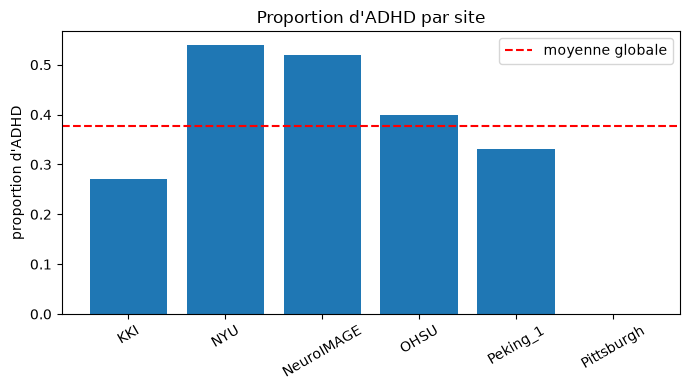

In [21]:
#le mm resultat sous forme de graphique
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(resume_site.index, resume_site["taux_adhd"])
ax.axhline(df["adhd"].mean(), linestyle="--", color="red", label="moyenne globale")
ax.set_ylabel("proportion d'ADHD")
ax.set_title("Proportion d'ADHD par site")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

      count   mean   std
adhd                    
0       405  12.08  3.32
1       245  11.31  3.09


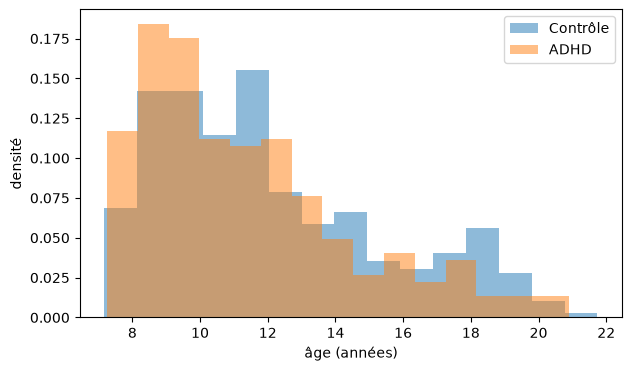

In [22]:
#l’âge selon le diagnostic
print(df.groupby("adhd")["age"].agg(["count", "mean", "std"]).round(2))

fig, ax = plt.subplots(figsize=(7, 4))
for valeur, nom in [(0, "Contrôle"), (1, "ADHD")]:
    ax.hist(df.loc[df["adhd"] == valeur, "age"], bins=15,
            alpha=0.5, density=True, label=nom)
ax.set_xlabel("âge (années)")
ax.set_ylabel("densité")
ax.legend()
plt.show()

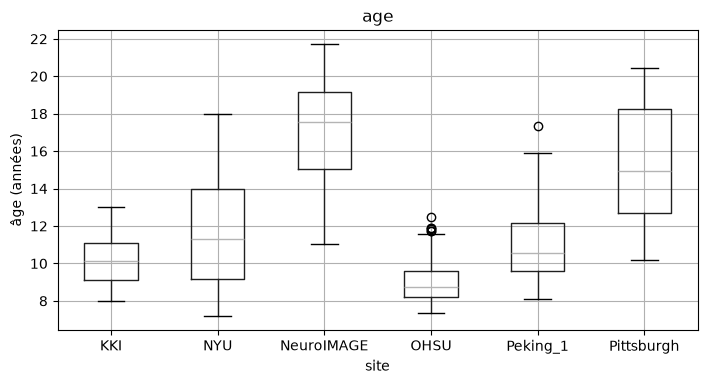

In [23]:
#l’âge selon le site
df.boxplot(column="age", by="site", figsize=(8, 4))
plt.suptitle("")
plt.ylabel("âge (années)")
plt.show()

In [24]:
#sexe et QI selon le diagnostic
print("Proportion de garçons (sexe = 1) par groupe :")
print(df.groupby("adhd")["sexe"].mean().round(2))

print("\nQI par groupe :")
print(df.groupby("adhd")["iq"].agg(["count", "mean", "std"]).round(1))

Proportion de garçons (sexe = 1) par groupe :
adhd
0    0.46
1    0.73
Name: sexe, dtype: float64

QI par groupe :
      count   mean   std
adhd                    
0       375  113.1  13.2
1       217  105.9  14.0
